In [1]:
import os
import pickle
import regionmask
import numpy as np
import pandas as pd
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from shapely.geometry import box
from scipy.stats import ttest_ind

In [2]:
def to_month_start_on_time(ds: xr.Dataset) -> xr.Dataset:
    """
    Force ds.time to the first day of each month.
    Works for both ERA5 and GRACE monthly data.
    """
    t = pd.to_datetime(ds.indexes["time"]).to_period("M").to_timestamp()  # month-end by default
    t = t - pd.offsets.MonthEnd(1) + pd.offsets.Day(1)  # shift to first day
    return ds.assign_coords(time=t)

In [3]:
out = "/home/mgurazada/snowdroughts_thirst/data/era5_monthly/era5_monthly_processed"
era5_path = os.path.join(out, "era5_data.nc")
era5_data = xr.open_dataset(era5_path)
# subset ERA5 from 2002-04-01 onwards (no upper bound yet)
era5_data = era5_data.sel(time=slice("1950-04-01", None))
era5_data = to_month_start_on_time(era5_data)
ppt = era5_data['ppt']
ppt

<xarray.DataArray 'ppt' (time: 897, lat: 721, lon: 1440)> Size: 4GB
[931301280 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 7kB 1950-04-01 1950-05-01 ... 2024-12-01
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Attributes:
    units:              mm
    description:        monthly total precipitation
    dimensions:         lon lat time
    grid_mapping:       crs
    coordinate_system:  WGS84,EPSG:4326

In [4]:
hb = gpd.read_file("/home/mgurazada/snowdroughts_thirst/data/hydrobasins/hydrobasins_global_lev04.shp")

# restrict to 0–60N if you are using that domain

bbox_geom = box(-180, 0, 180, 60)
hb = hb[hb.geometry.intersects(bbox_geom)].copy()

# simplify + fix geometry
hb["geometry"] = hb.geometry.simplify(0.01, preserve_topology=True)
hb["geometry"] = hb.geometry.buffer(0)

# dissolve per MAIN_BAS
geoms   = []
names   = []
abbrevs = []
main_ids_valid = []

for mid in np.sort(hb["MAIN_BAS"].unique()):
    basin = hb[hb["MAIN_BAS"] == mid]

    geom = basin.geometry.union_all().buffer(0)

    if geom.is_empty:
        continue

    geoms.append(geom)
    names.append(f"basin_{mid}")
    abbrevs.append(str(mid))
    main_ids_valid.append(mid)

regions = regionmask.Regions(geoms, names=names, abbrevs=abbrevs)

# map basin → region index
basin_to_region_index = {bid: i for i, bid in enumerate(main_ids_valid)}

In [5]:
mask_era5 = regions.mask_3D(
    era5_data["lon"],
    era5_data["lat"],
    drop=False
)
mask_era5

/home/mgurazada/.conda/envs/myenv/lib/python3.11/site-packages/regionmask/core/mask.py:406: UserWarning: Detected overlapping regions. As of v0.11.0 these are correctly taken into account. Note, however, that a different mask is returned than with older versions of regionmask. To suppress this warning, set `overlap=True` (to restore the old, incorrect, behaviour, set `overlap=False`).
  warnings.warn(


<xarray.DataArray 'mask' (region: 602, lat: 721, lon: 1440)> Size: 625MB
array([[[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
...
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]],

       [[False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        ...,
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False],
        [False, False, False, ..., False, False, False]]],
      shape=(602, 721, 1440))
Coordinates:
  * region   (region) int64 5kB 0 1 2 3 4 5 6 7 ... 595 596 597 598 599 600 601
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
    abbrevs  (region) <U10 24kB '1040000010' '1040003990' ... '9040005890'
    names    (region) <U16 39kB 'basin_1040000010' ... 'basin_9040005890'
Attributes:
    standard_name:  region

In [6]:
print("n MAIN_BAS ids:", len(main_ids_valid))
print("n regions:", len(regions))
print("mask_era5 n_regions:", mask_era5.sizes["region"])

n MAIN_BAS ids: 602
n regions: 602
mask_era5 n_regions: 602


In [7]:
snow = xr.open_dataset("/home/mgurazada/snowdroughts_thirst/data/snow_cover/data/snow_mask_monthly_climatology/modis_nsidc_snow_mask_monthly_0p05deg.nc")

snow_var = list(snow.data_vars)[0]
snow_clim = snow[snow_var]

# winter months
snow_winter = snow_clim.sel(month=[12,1,2,3])

# snow anywhere in winter
snow_mask = (snow_winter == 1).any(dim="month")

# regrid to ERA5
snow_on_era5 = snow_mask.astype("float32").interp(
    lat=era5_data["lat"],
    lon=era5_data["lon"],
    method="nearest"
) > 0.5

In [8]:
crop = xr.open_dataset("/home/mgurazada/snowdroughts_thirst/data/cropland/Global_cropland_3km_2019.nc")

crop_var = list(crop.data_vars)[1]
cropland = crop[crop_var]

# rename if needed
if "x" in cropland.dims:
    cropland = cropland.rename({"y":"lat","x":"lon"})

# ensure ascending lat
if (cropland.lat.diff("lat") < 0).any():
    cropland = cropland.sortby("lat")

cropland_any = cropland > 0

crop_on_era5 = cropland_any.astype("float32").interp(
    lat=era5_data["lat"],
    lon=era5_data["lon"],
    method="nearest"
) > 0.5


In [9]:
def basin_mean(da, mask):
    """
    da: DataArray with dims (time, lat, lon) or (..., lat, lon)
    mask: boolean DataArray with dims (lat, lon) for ONE basin
    """
    da_basin = da.where(mask)
    w = np.cos(np.deg2rad(da_basin["lat"]))  # 1D, broadcasts over lon
    return da_basin.weighted(w).mean(dim=("lat", "lon"), skipna=True)

def frac_within_basin(basin_mask, condition_mask):
    """
    Area-weighted fraction of basin area that meets condition.
    basin_mask: boolean (lat, lon) True inside basin
    condition_mask: boolean (lat, lon) True where condition holds
    """
    w = np.cos(np.deg2rad(basin_mask["lat"]))
    basin_area = basin_mask.astype(float).weighted(w).sum(dim=("lat", "lon"), skipna=True)
    cond_area  = (basin_mask & condition_mask).astype(float).weighted(w).sum(dim=("lat", "lon"), skipna=True)
    if float(basin_area) == 0.0:
        return 0.0
    return float(cond_area / basin_area)

In [10]:
SNOW_FRAC_MIN = 0.05   # ≥5% basin has winter snow
CROP_FRAC_MIN = 0.05   # ≥5% basin has cropland

In [11]:
# Basin-mean monthly total precip z-score series
ppt_by_basin = {}

for bid in main_ids_valid:
    i = basin_to_region_index[bid]
    m_era5 = mask_era5.isel(region=i)  # basin mask on ERA5 grid

    # keep consistent with basin screening
    snow_frac = frac_within_basin(m_era5, snow_on_era5)
    crop_frac = frac_within_basin(m_era5, crop_on_era5)

    if (snow_frac < SNOW_FRAC_MIN) or (crop_frac < CROP_FRAC_MIN):
        ppt_by_basin[bid] = None
        continue

    # subset to speed up
    lat_sel = m_era5.any(dim="lon")
    lon_sel = m_era5.any(dim="lat")

    ppt_sub  = ppt.isel(lat=lat_sel, lon=lon_sel)
    mask_sub  = m_era5.isel(lat=lat_sel, lon=lon_sel)

    ppt_by_basin[bid] = basin_mean(ppt_sub, mask_sub)

print("Basins with ppt:", sum(v is not None for v in ppt_by_basin.values()))


Basins with ppt: 174


In [12]:
def water_year(time):
    year = time.dt.year
    month = time.dt.month
    return xr.where(month >= 10, year + 1, year)

def seasonal_zscore(da, baseline_start="2003", baseline_end="2024"):
    """
    da: seasonal basin series with dim 'wy'
    z-score is computed on the aggregated seasonal values across water years
    """
    base = da.sel(wy=slice(int(baseline_start), int(baseline_end)))
    mu = base.mean("wy", skipna=True)
    sigma = base.std("wy", skipna=True)
    return (da - mu) / sigma
    
ppt_fall_by_basin = {}
ppt_winter_by_basin = {}
ppt_summer_by_basin = {}

for bid in main_ids_valid:
    pr_ts = ppt_by_basin.get(bid)
    if pr_ts is None:
        continue

    pr_ts = pr_ts.assign_coords(wy=water_year(pr_ts.time))

    # fall precip z (Sep–Nov)
    is_fall = pr_ts.time.dt.month.isin([9, 10, 11])
    pr_fall = pr_ts.where(is_fall, drop=True).groupby("wy").sum("time")
    ppt_fall_by_basin[bid] = seasonal_zscore(pr_fall)

    # Winter precip z (Dec–Apr)
    is_winter = pr_ts.time.dt.month.isin([12, 1, 2, 3])
    pr_winter = pr_ts.where(is_winter, drop=True).groupby("wy").sum("time")
    ppt_winter_by_basin[bid] = seasonal_zscore(pr_winter)

    # Summer precip z (Apr–Sep)
    is_summer = pr_ts.time.dt.month.isin([4, 5, 6, 7, 8, 9])
    pr_summer = pr_ts.where(is_summer, drop=True).groupby("wy").sum("time")
    ppt_summer_by_basin[bid] = seasonal_zscore(pr_summer)

# quick check on one basin
test_bid = next(b for b in ppt_winter_by_basin if ppt_winter_by_basin[b] is not None)
print("Example basin:", test_bid)
print("Fall WY precip z:", ppt_fall_by_basin[test_bid].isel(wy=slice(0, 5)))
print("Winter WY precip z:", ppt_winter_by_basin[test_bid].isel(wy=slice(0, 5)))
print("Summer WY precip z:", ppt_summer_by_basin[test_bid].isel(wy=slice(0, 5)))

Example basin: 1040029430
Fall WY precip z: <xarray.DataArray 'ppt' (wy: 5)> Size: 40B
array([-1.66737531, -0.1256931 ,  0.65592138, -0.75858711, -0.32049699])
Coordinates:
  * wy       (wy) int64 40B 1950 1951 1952 1953 1954
    region   int64 8B 40
    abbrevs  <U10 40B '1040029430'
    names    <U16 64B 'basin_1040029430'
Winter WY precip z: <xarray.DataArray 'ppt' (wy: 5)> Size: 40B
array([ 1.38927915, -0.25712909,  0.86175133,  1.86032672,  1.46661458])
Coordinates:
  * wy       (wy) int64 40B 1951 1952 1953 1954 1955
    region   int64 8B 40
    abbrevs  <U10 40B '1040029430'
    names    <U16 64B 'basin_1040029430'
Summer WY precip z: <xarray.DataArray 'ppt' (wy: 5)> Size: 40B
array([-1.03925939, -1.15813271, -0.18902537, -0.92677972, -0.21752545])
Coordinates:
  * wy       (wy) int64 40B 1950 1951 1952 1953 1954
    region   int64 8B 40
    abbrevs  <U10 40B '1040029430'
    names    <U16 64B 'basin_1040029430'


In [13]:
swe = era5_data["swe"]

swe_by_basin = {}

for bid in main_ids_valid:

    i = basin_to_region_index[bid]
    m_era5 = mask_era5.isel(region=i)

    # screening
    snow_frac = frac_within_basin(m_era5, snow_on_era5)
    crop_frac = frac_within_basin(m_era5, crop_on_era5)

    if (snow_frac < SNOW_FRAC_MIN) or (crop_frac < CROP_FRAC_MIN):
        swe_by_basin[bid] = None
        continue

    # SWE ONLY over snow-covered pixels
    m_swe = m_era5 & snow_on_era5

    if not bool(m_swe.any()):
        swe_by_basin[bid] = None
        continue

    lat_sel = m_swe.any(dim="lon")
    lon_sel = m_swe.any(dim="lat")

    swe_sub  = swe.isel(lat=lat_sel, lon=lon_sel)
    mask_sub = m_swe.isel(lat=lat_sel, lon=lon_sel)

    swe_by_basin[bid] = basin_mean(swe_sub, mask_sub)

print("Basins with SWE:", sum(v is not None for v in swe_by_basin.values()))

swe_peak_by_basin = {}

for bid in main_ids_valid:
    swe_ts = swe_by_basin.get(bid)
    if swe_ts is None:
        continue

    # add water-year coordinate
    swe_ts = swe_ts.assign_coords(wy=water_year(swe_ts.time))

    # peak SWE during winter (Dec–Apr)
    is_winter = swe_ts.time.dt.month.isin([12, 1, 2, 3])
    swe_peak = (
        swe_ts
        .where(is_winter, drop=True)
        .groupby("wy")
        .max("time")
    )

    swe_peak_by_basin[bid] = swe_peak

Basins with SWE: 174


Example basin: 1040029430
<xarray.DataArray 'swe' (wy: 75)> Size: 600B
array([53.30254233, 21.38480987, 48.93315164, 56.81909755, 23.26179265,
       38.24397774,  9.80677008, 93.87540141,  9.40487253, 29.47582192,
       63.03735746, 19.92377051, 14.36785738,  8.19792216, 39.65570268,
        5.15165949, 16.26945589, 15.08084306, 14.83934   ,  7.92474102,
       33.82190173, 58.6779976 , 44.54492305, 28.35326831,  3.84832229,
       18.45983426, 26.9482501 , 17.39195412, 30.32140863, 10.46401646,
       10.22036499, 10.71731431, 14.24150073,  3.63610641, 33.25353225,
       24.13622155, 23.63196203, 15.97501829, 14.74773639, 18.56750941,
       23.24278768,  4.43379554, 23.29519324, 39.71564869,  3.80460101,
       23.00759835,  9.87353155,  2.41699224, 33.25684663,  3.27022098,
       16.20362653,  2.58751187,  9.13273926, 11.73994559,  6.54778819,
       36.90673335, 17.11201848, 19.97851793, 47.02822666,  8.14976564,
        3.95172329,  7.03005888,  6.67094642,  8.59633466, 24.157

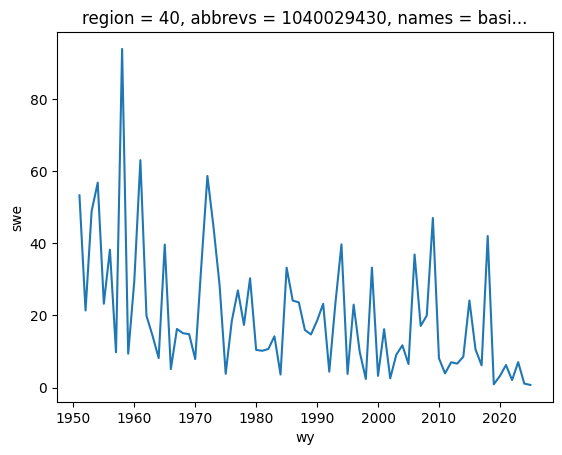

In [14]:
bid = next(b for b in main_ids_valid if swe_peak_by_basin.get(b) is not None)

print("Example basin:", bid)
print(swe_peak_by_basin[bid])
swe_peak_by_basin[bid].plot()

In [15]:
eto = era5_data["eto"]

eto_by_basin = {}

for bid in main_ids_valid:
    i = basin_to_region_index[bid]
    m_era5 = mask_era5.isel(region=i)

    # screening (same as SWE)
    snow_frac = frac_within_basin(m_era5, snow_on_era5)
    crop_frac = frac_within_basin(m_era5, crop_on_era5)

    if (snow_frac < SNOW_FRAC_MIN) or (crop_frac < CROP_FRAC_MIN):
        eto_by_basin[bid] = None
        continue

    # ETo ONLY over cropland pixels
    m_eto = m_era5 & crop_on_era5

    if not bool(m_eto.any()):
        eto_by_basin[bid] = None
        continue

    lat_sel = m_eto.any(dim="lon")
    lon_sel = m_eto.any(dim="lat")

    eto_sub  = eto.isel(lat=lat_sel, lon=lon_sel)
    mask_sub = m_eto.isel(lat=lat_sel, lon=lon_sel)

    eto_by_basin[bid] = basin_mean(eto_sub, mask_sub)

print("Basins with ETo:", sum(v is not None for v in eto_by_basin.values()))


Basins with ETo: 174


In [16]:
eto_summer_by_basin = {}

for bid in main_ids_valid:
    eto_ts = eto_by_basin.get(bid)
    if eto_ts is None:
        continue

    eto_ts = eto_ts.assign_coords(wy=water_year(eto_ts.time))

    is_summer = eto_ts.time.dt.month.isin([4, 5, 6, 7, 8, 9])
    eto_summer = (
        eto_ts
        .where(is_summer, drop=True)
        .groupby("wy")
        .mean("time")
    )

    eto_summer_by_basin[bid] = eto_summer

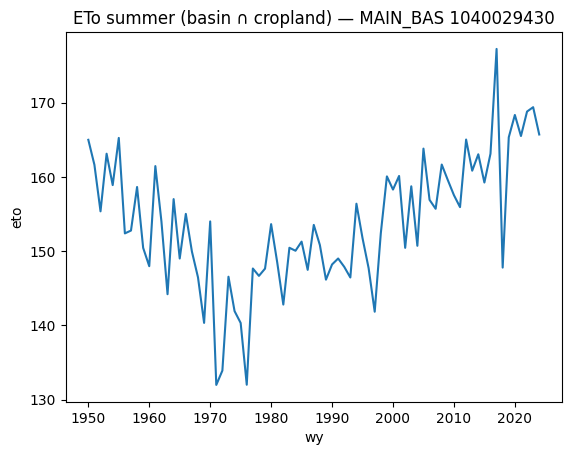

In [17]:
bid = next(b for b in main_ids_valid if eto_summer_by_basin.get(b) is not None)
eto_summer_by_basin[bid].plot()
plt.title(f"ETo summer (basin ∩ cropland) — MAIN_BAS {bid}")
plt.show()

In [18]:
q_lo, q_hi = 0.30, 0.70
class_by_basin = {}

for bid in main_ids_valid:

    swe_peak = swe_peak_by_basin.get(bid)
    eto_summer = eto_summer_by_basin.get(bid)

    if (swe_peak is None) or (eto_summer is None):
        continue

    # align WY
    common_wy = np.intersect1d(swe_peak.wy.values, eto_summer.wy.values)
    if len(common_wy) == 0:
        continue

    swe_b = swe_peak.sel(wy=common_wy)
    eto_b = eto_summer.sel(wy=common_wy)

    # drop NaNs
    valid = np.isfinite(swe_b.values) & np.isfinite(eto_b.values)
    swe_b = swe_b.isel(wy=valid)
    eto_b = eto_b.isel(wy=valid)

    if swe_b.sizes["wy"] == 0:
        continue

    common_wy = swe_b.wy.values.astype(int)

    swe_tlow  = float(swe_b.quantile(q_lo, dim="wy"))
    eto_thigh = float(eto_b.quantile(q_hi, dim="wy"))

    low_swe  = swe_b <= swe_tlow
    high_eto = eto_b >= eto_thigh

    df_class = pd.DataFrame({
        "WY": common_wy,
        "normal": (~low_swe & ~high_eto).values,
        "low_swe_only": (low_swe & ~high_eto).values,
        "high_eto_only": (~low_swe & high_eto).values,
        "low_swe_high_eto": (low_swe & high_eto).values,
    })

    class_by_basin[bid] = df_class

In [19]:
def wy_values_for_class(df_class, col):
    return df_class.loc[df_class[col], "WY"].astype(int).tolist()

def sel_vals(da, wys):
    if (da is None) or (not wys):
        return np.array([])

    da_wy = da["wy"].values.astype(int)
    wys_ok = np.intersect1d(da_wy, np.array(wys, dtype=int))

    if len(wys_ok) == 0:
        return np.array([])

    out = da.sel(wy=wys_ok).values
    return out[np.isfinite(out)]

precip_by_basin = {}

for bid in main_ids_valid:
    df_class = class_by_basin.get(bid)
    pr_fall = ppt_fall_by_basin.get(bid)
    pr_winter = ppt_winter_by_basin.get(bid)
    pr_summer = ppt_summer_by_basin.get(bid)

    if (df_class is None) or (pr_winter is None) or (pr_summer is None):
        continue

    wy_normal   = wy_values_for_class(df_class, "normal")
    wy_snowonly = wy_values_for_class(df_class, "low_swe_only")
    wy_demonly  = wy_values_for_class(df_class, "high_eto_only")
    wy_comp     = wy_values_for_class(df_class, "low_swe_high_eto")

    precip_by_basin[bid] = {
        "fall": {
            "normal":      sel_vals(pr_fall, wy_normal),
            "snow_only":   sel_vals(pr_fall, wy_snowonly),
            "demand_only": sel_vals(pr_fall, wy_demonly),
            "compound":    sel_vals(pr_fall, wy_comp),
        },
        "winter": {
            "normal":      sel_vals(pr_winter, wy_normal),
            "snow_only":   sel_vals(pr_winter, wy_snowonly),
            "demand_only": sel_vals(pr_winter, wy_demonly),
            "compound":    sel_vals(pr_winter, wy_comp),
        },
        "summer": {
            "normal":      sel_vals(pr_summer, wy_normal),
            "snow_only":   sel_vals(pr_summer, wy_snowonly),
            "demand_only": sel_vals(pr_summer, wy_demonly),
            "compound":    sel_vals(pr_summer, wy_comp),
        }
    }

print("Basins with precip_by_basin:", len(precip_by_basin))

Basins with precip_by_basin: 174


In [20]:
bid = next(iter(precip_by_basin.keys()))
for season in ["fall", "winter", "summer"]:
    print(season, {k: len(v) for k, v in precip_by_basin[bid][season].items()})


fall {'normal': 40, 'snow_only': 12, 'demand_only': 12, 'compound': 10}
winter {'normal': 40, 'snow_only': 12, 'demand_only': 12, 'compound': 10}
summer {'normal': 40, 'snow_only': 12, 'demand_only': 12, 'compound': 10}


/tmp/ipykernel_2247024/3658561190.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


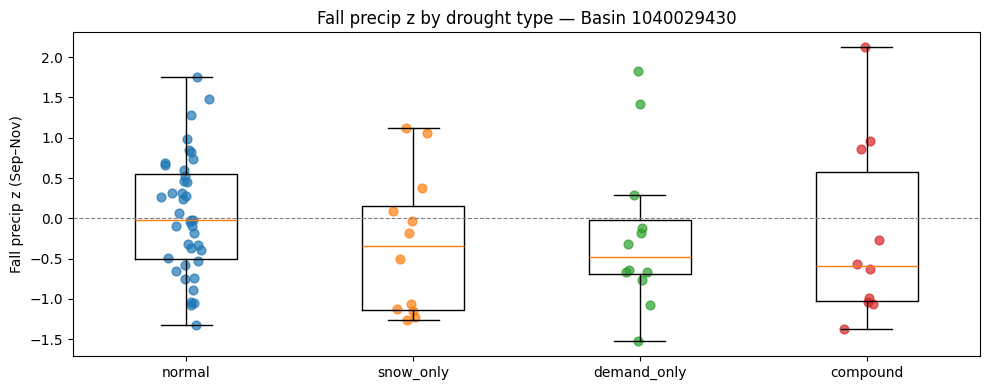

/tmp/ipykernel_2247024/3658561190.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


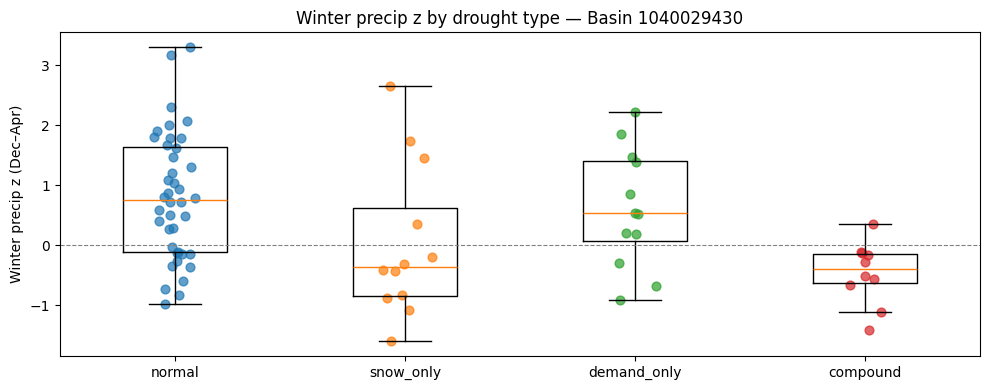

/tmp/ipykernel_2247024/3658561190.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


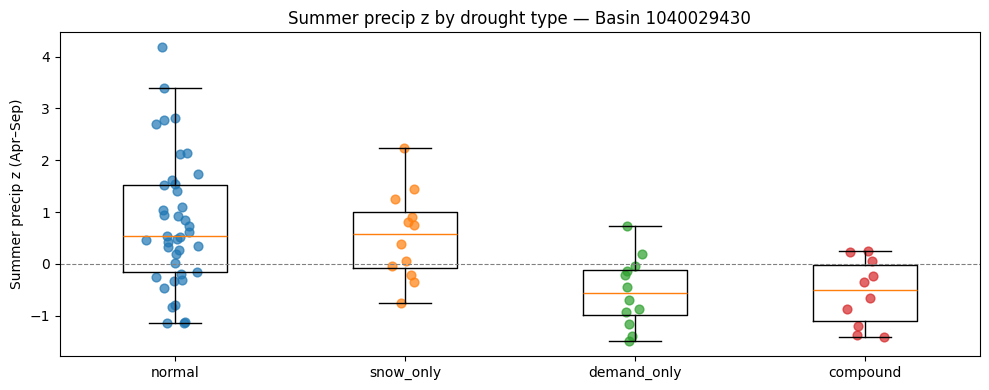

In [21]:
bid = next(iter(precip_by_basin.keys()))
labels = ["normal", "snow_only", "demand_only", "compound"]

def box_with_points(season, ylabel, title):
    data = [precip_by_basin[bid][season][k] for k in labels]

    plt.figure(figsize=(10,4))
    plt.boxplot(data, labels=labels, showfliers=False)

    # add individual points with jitter
    for i, y in enumerate(data, start=1):
        if len(y) == 0:
            continue
        x = np.random.normal(i, 0.05, size=len(y))  # jitter
        plt.scatter(x, y, alpha=0.7, s=40)

    plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    plt.ylabel(ylabel)
    plt.title(f"{title} — Basin {bid}")
    plt.tight_layout()
    plt.show()

box_with_points("fall",   "Fall precip z (Sep–Nov)",   "Fall precip z by drought type")
box_with_points("winter", "Winter precip z (Dec–Apr)", "Winter precip z by drought type")
box_with_points("summer", "Summer precip z (Apr–Sep)", "Summer precip z by drought type")

/tmp/ipykernel_2247024/3658561190.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


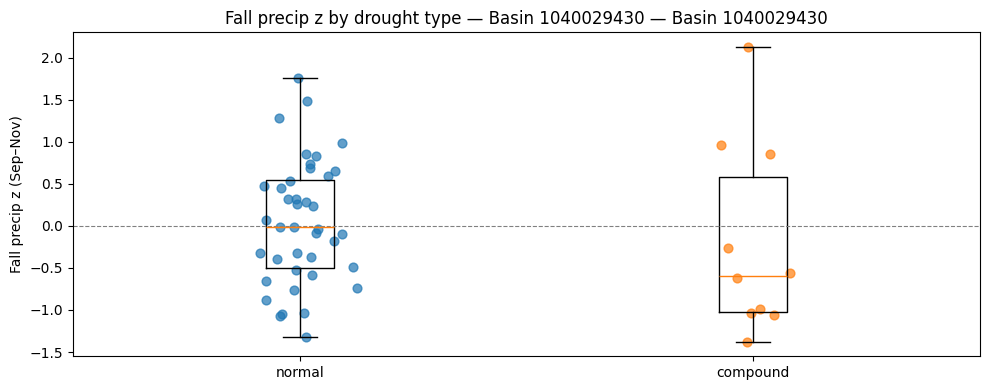

/tmp/ipykernel_2247024/3658561190.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


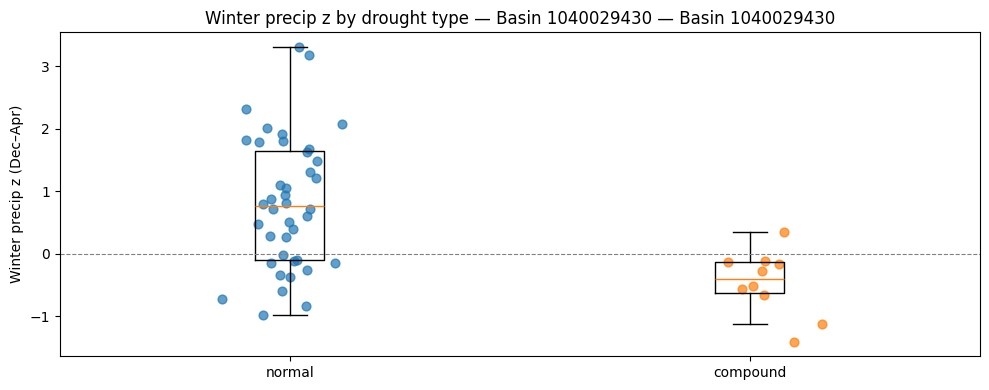

/tmp/ipykernel_2247024/3658561190.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=False)


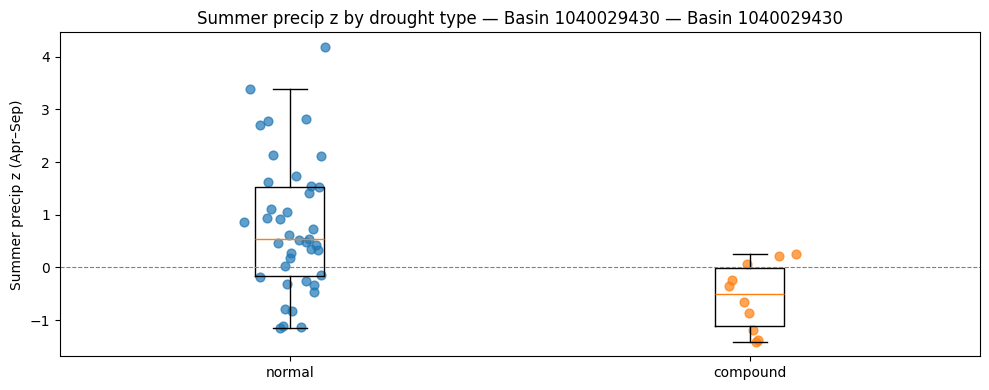

In [22]:
bid = 1040029430
labels = ["normal", "compound"]

if bid not in precip_by_basin:
    print("This basin has no precip data in precip_by_basin.")
else:
    box_with_points("fall",   "Fall precip z (Sep–Nov)",   f"Fall precip z by drought type — Basin {bid}")
    box_with_points("winter", "Winter precip z (Dec–Apr)", f"Winter precip z by drought type — Basin {bid}")
    box_with_points("summer", "Summer precip z (Apr–Sep)", f"Summer precip z by drought type — Basin {bid}")

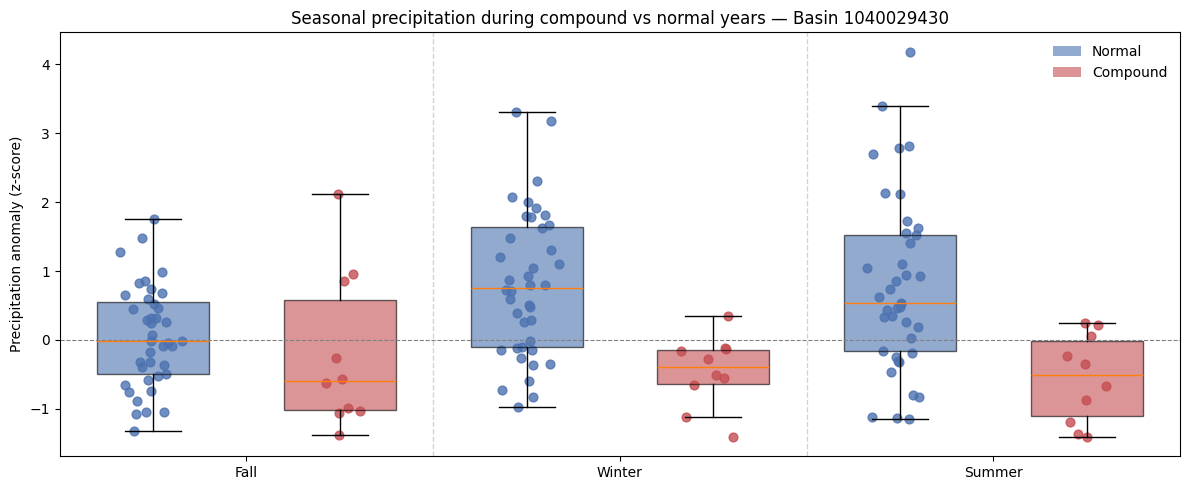

In [23]:
labels = ["normal", "compound"]
seasons = ["fall", "winter", "summer"]

plt.figure(figsize=(12,5))

positions = []
data = []
colors = []
xticks = []
pos = 1

for season in seasons:
    for k in labels:
        arr = precip_by_basin[bid][season][k]
        data.append(arr)
        positions.append(pos)

        # assign colors
        colors.append("#4C72B0" if k == "normal" else "#C44E52")
        pos += 1

    xticks.append(pos - 1.5)

# draw boxplots
bp = plt.boxplot(
    data,
    positions=positions,
    widths=0.6,
    showfliers=False,
    patch_artist=True
)

# color boxes
for patch, c in zip(bp["boxes"], colors):
    patch.set_facecolor(c)
    patch.set_alpha(0.6)

# overlay points with same colors
for p, arr, c in zip(positions, data, colors):
    if len(arr) == 0:
        continue
    x = np.random.normal(p, 0.08, size=len(arr))
    plt.scatter(x, arr, color=c, alpha=0.8, s=40)

# season labels
plt.xticks(xticks, ["Fall", "Winter", "Summer"])

# separators
plt.axvline(2.5, color="lightgray", linestyle="--", linewidth=1)
plt.axvline(4.5, color="lightgray", linestyle="--", linewidth=1)

plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
plt.ylabel("Precipitation anomaly (z-score)")
plt.title(f"Seasonal precipitation during compound vs normal years — Basin {bid}")

# legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor="#4C72B0", alpha=0.6, label="Normal"),
    Patch(facecolor="#C44E52", alpha=0.6, label="Compound")
]
plt.legend(handles=legend_elements, frameon=False)

plt.tight_layout()
plt.show()

In [24]:
for bid in list(class_by_basin.keys())[:10]:
    df = class_by_basin[bid]
    print(bid, df[["normal","low_swe_only","high_eto_only","low_swe_high_eto"]].sum().to_dict())

1040029430 {'normal': 40, 'low_swe_only': 12, 'high_eto_only': 12, 'low_swe_high_eto': 10}
1040029700 {'normal': 40, 'low_swe_only': 12, 'high_eto_only': 12, 'low_swe_high_eto': 10}
2040000010 {'normal': 39, 'low_swe_only': 13, 'high_eto_only': 13, 'low_swe_high_eto': 9}
2040003440 {'normal': 40, 'low_swe_only': 12, 'high_eto_only': 12, 'low_swe_high_eto': 10}
2040003550 {'normal': 42, 'low_swe_only': 10, 'high_eto_only': 10, 'low_swe_high_eto': 12}
2040003560 {'normal': 43, 'low_swe_only': 9, 'high_eto_only': 9, 'low_swe_high_eto': 13}
2040004130 {'normal': 39, 'low_swe_only': 13, 'high_eto_only': 13, 'low_swe_high_eto': 9}
2040004140 {'normal': 40, 'low_swe_only': 12, 'high_eto_only': 12, 'low_swe_high_eto': 10}
2040004280 {'normal': 40, 'low_swe_only': 12, 'high_eto_only': 12, 'low_swe_high_eto': 10}
2040004290 {'normal': 41, 'low_swe_only': 11, 'high_eto_only': 11, 'low_swe_high_eto': 11}


In [25]:
# mech_by_basin = {}

# for bid, d in precip_by_basin.items():
#     w = d["winter"]
#     s = d["summer"]

#     def m(x): 
#         return float(np.mean(x)) if len(x) > 0 else np.nan

#     mech_by_basin[bid] = {
#         "winter_mean_normal":   m(w["normal"]),
#         "winter_mean_snowonly": m(w["snow_only"]),
#         "winter_mean_demonly":  m(w["demand_only"]),
#         "winter_mean_compound": m(w["compound"]),
#         "summer_mean_normal":   m(s["normal"]),
#         "summer_mean_snowonly": m(s["snow_only"]),
#         "summer_mean_demonly":  m(s["demand_only"]),
#         "summer_mean_compound": m(s["compound"]),
#         "n_winter_snowonly": len(w["snow_only"]),
#         "n_summer_snowonly": len(s["snow_only"]),
#         "n_winter_demandonly": len(w["demand_only"]),
#         "n_summer_demandonly": len(s["demand_only"]),
#         "n_winter_compound": len(w["compound"]),
#         "n_summer_compound": len(s["compound"]),
#     }

# # quick peek
# some_bid = next(iter(mech_by_basin.keys()))
# print(some_bid, mech_by_basin[some_bid])

In [26]:
seasons = ["fall", "winter", "summer"]
classes = ["normal", "snow_only", "demand_only", "compound"]

mech_by_basin = {}

for bid, d in precip_by_basin.items():
    out = {}

    for season in seasons:
        for cls in classes:
            arr = d[season][cls]
            out[f"{season}_mean_{cls}"] = float(np.mean(arr)) if len(arr) > 0 else np.nan
            out[f"n_{season}_{cls}"] = int(len(arr))

    mech_by_basin[bid] = out

# quick peek
some_bid = next(iter(mech_by_basin.keys()))
print(some_bid, mech_by_basin[some_bid])

1040029430 {'fall_mean_normal': 0.04543060839083719, 'n_fall_normal': 40, 'fall_mean_snow_only': -0.3247295359423676, 'n_fall_snow_only': 12, 'fall_mean_demand_only': -0.20269032482629623, 'n_fall_demand_only': 12, 'fall_mean_compound': -0.19723634126726156, 'n_fall_compound': 10, 'winter_mean_normal': 0.8082879613582532, 'n_winter_normal': 40, 'winter_mean_snow_only': 0.04012833430434399, 'n_winter_snow_only': 12, 'winter_mean_demand_only': 0.6161029218788977, 'n_winter_demand_only': 12, 'winter_mean_compound': -0.46016218828727834, 'n_winter_compound': 10, 'summer_mean_normal': 0.7765911868539784, 'n_summer_normal': 40, 'summer_mean_snow_only': 0.5428516516037994, 'n_summer_snow_only': 12, 'summer_mean_demand_only': -0.5372818931769633, 'n_summer_demand_only': 12, 'summer_mean_compound': -0.5548849551348616, 'n_summer_compound': 10}


In [27]:
# Welch t-tests for precip (compound vs normal) by season
seasons = ["fall", "winter", "summer"]
alpha = 0.05

ppt_ttest_results = {}  # ppt_ttest_results[bid][season] = {mean_diff, p_value, n_A, n_B}

for bid, d in precip_by_basin.items():
    basin_res = {}

    for season in seasons:
        a = d[season]["compound"]  # group A
        b = d[season]["normal"]    # group B

        # require at least 2 years per group (same rule as your SWSA code)
        if (len(a) < 2) or (len(b) < 2):
            continue

        tstat, pval = ttest_ind(a, b, equal_var=False, nan_policy="omit")

        basin_res[season] = {
            "mean_diff": float(np.nanmean(a) - np.nanmean(b)),  # compound - normal
            "p_value": float(pval),
            "n_A": int(len(a)),
            "n_B": int(len(b)),
        }

    if basin_res:
        ppt_ttest_results[bid] = basin_res

In [28]:
# Build per-basin Δprecip (compound − normal) + p-value dicts

delta_ppt_by_basin = {s: {} for s in seasons}
p_ppt_by_basin     = {s: {} for s in seasons}

for bid in main_ids_valid:
    res = ppt_ttest_results.get(bid, {})

    for s in seasons:
        if s in res:
            delta_ppt_by_basin[s][bid] = res[s]["mean_diff"]
            p_ppt_by_basin[s][bid]     = res[s]["p_value"]
        else:
            delta_ppt_by_basin[s][bid] = np.nan
            p_ppt_by_basin[s][bid]     = np.nan

In [29]:
basins_diss = hb.dissolve(by="MAIN_BAS").reset_index()
basins_diss["MAIN_BAS"] = basins_diss["MAIN_BAS"].astype(int)

basins_diss["fall_comp"] = basins_diss["MAIN_BAS"].map(
    lambda x: mech_by_basin.get(int(x), {}).get("fall_mean_compound", np.nan)
)
basins_diss["winter_comp"] = basins_diss["MAIN_BAS"].map(
    lambda x: mech_by_basin.get(int(x), {}).get("winter_mean_compound", np.nan)
)
basins_diss["summer_comp"] = basins_diss["MAIN_BAS"].map(
    lambda x: mech_by_basin.get(int(x), {}).get("summer_mean_compound", np.nan)
)
basins_diss["n_comp"] = basins_diss["MAIN_BAS"].map(
    lambda x: mech_by_basin.get(int(x), {}).get("n_winter_compound", 0)
)

basins_diss["fall_norm"] = basins_diss["MAIN_BAS"].map(
    lambda x: mech_by_basin.get(int(x), {}).get("fall_mean_normal", np.nan)
)
basins_diss["winter_norm"] = basins_diss["MAIN_BAS"].map(
    lambda x: mech_by_basin.get(int(x), {}).get("winter_mean_normal", np.nan)
)
basins_diss["summer_norm"] = basins_diss["MAIN_BAS"].map(
    lambda x: mech_by_basin.get(int(x), {}).get("summer_mean_normal", np.nan)
)

basins_diss["n_norm"] = basins_diss["MAIN_BAS"].map(
    lambda x: mech_by_basin.get(int(x), {}).get("n_winter_normal", 0)
)

print(basins_diss[["fall_comp","winter_comp","summer_comp"]].notna().sum())

fall_comp      174
winter_comp    174
summer_comp    174
dtype: int64


In [30]:
basins_diss["dPPT_fall_comp_minus_norm"]   = basins_diss["MAIN_BAS"].map(delta_ppt_by_basin["fall"])
basins_diss["dPPT_winter_comp_minus_norm"] = basins_diss["MAIN_BAS"].map(delta_ppt_by_basin["winter"])
basins_diss["dPPT_summer_comp_minus_norm"] = basins_diss["MAIN_BAS"].map(delta_ppt_by_basin["summer"])

In [31]:
print("Basins total:", len(basins_diss))
print("fall_comp notna:", basins_diss["fall_comp"].notna().sum())
print("winter_comp notna:", basins_diss["winter_comp"].notna().sum())
print("summer_comp notna:", basins_diss["summer_comp"].notna().sum())
print("fall_norm notna:", basins_diss["fall_norm"].notna().sum())
print("winter_norm notna:", basins_diss["winter_norm"].notna().sum())
print("summer_norm notna:", basins_diss["summer_norm"].notna().sum())

Basins total: 602
fall_comp notna: 174
winter_comp notna: 174
summer_comp notna: 174
fall_norm notna: 173
winter_norm notna: 173
summer_norm notna: 173


In [32]:
# # dissolve to one polygon per MAIN_BAS
# basins_diss = hb.dissolve(by="MAIN_BAS").reset_index()

# # attach compound precip metrics
# basins_diss["winter_comp"] = basins_diss["MAIN_BAS"].map(
#     lambda x: mech_by_basin.get(x, {}).get("winter_mean_compound", np.nan)
# )

# basins_diss["summer_comp"] = basins_diss["MAIN_BAS"].map(
#     lambda x: mech_by_basin.get(x, {}).get("summer_mean_compound", np.nan)
# )

# basins_diss["n_comp"] = basins_diss["MAIN_BAS"].map(
#     lambda x: mech_by_basin.get(x, {}).get("n_winter_compound", 0)
# )


In [33]:
basins_diss.loc[basins_diss["n_comp"] == 0, "fall_comp"] = np.nan
basins_diss.loc[basins_diss["n_comp"] == 0, "winter_comp"] = np.nan
basins_diss.loc[basins_diss["n_comp"] == 0, "summer_comp"] = np.nan
basins_diss.loc[basins_diss["n_norm"] == 0, "fall_norm"] = np.nan
basins_diss.loc[basins_diss["n_norm"] == 0, "winter_norm"] = np.nan
basins_diss.loc[basins_diss["n_norm"] == 0, "summer_norm"] = np.nan

In [34]:
def plot_global_delta_ppt(column, title, p_dict=None, alpha=0.05):
    valid = basins_diss[basins_diss[column].notna()]
    if valid.empty:
        print(f"No data to plot for {column}")
        return

    vmin, vmax = -2.5, 2.5
    bounds = np.arange(vmin, vmax + 0.25, 0.25)
    n_bins = len(bounds) - 1

    cmap = plt.get_cmap("BrBG", n_bins)
    norm = mcolors.BoundaryNorm(bounds, ncolors=n_bins)

    fig = plt.figure(figsize=(12, 6))
    ax = plt.axes(projection=ccrs.Robinson())
    ax.set_global()

    ax.add_feature(cfeature.BORDERS, linewidth=0.6, edgecolor="gray")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6)

    basins_diss.plot(
        ax=ax,
        column=column,
        cmap=cmap,
        norm=norm,
        edgecolor="black",
        linewidth=0.2,
        legend=False,
        transform=ccrs.PlateCarree(),
        missing_kwds={
            "color": "lightgray",
            "edgecolor": "black",
            "label": "Insufficient data"
        },
    )

    if p_dict is not None:
        sig_ids = [
            bid for bid, p in p_dict.items()
            if (p is not None) and np.isfinite(p) and (p < alpha)
        ]
        print(f"{len(sig_ids)} significant basins (p < {alpha}) for {title}")

        sig_gdf = basins_diss[basins_diss["MAIN_BAS"].isin(sig_ids)]
        if not sig_gdf.empty:
            sig_gdf.plot(
                ax=ax,
                facecolor="none",
                edgecolor="black",
                linewidth=0.4,
                hatch="///",
                transform=ccrs.PlateCarree()
            )

            hatch_patch = mpatches.Patch(
                facecolor="none",
                edgecolor="black",
                hatch="///",
                label=f"p < {alpha}"
            )
            ax.legend(handles=[hatch_patch], loc="lower left",
                      bbox_to_anchor=(0.02, 0.02), frameon=False)

    ax.set_title(title, fontsize=14, pad=10)
    ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

    # place colorbar relative to map axes
    fig.canvas.draw()
    pos = ax.get_position()
    cax = fig.add_axes([pos.x0 + 0.03, pos.y0 - 0.10, pos.width - 0.12, 0.035])

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cb = fig.colorbar(sm, cax=cax, orientation="horizontal", ticks=bounds)
    cb.set_label("ΔPrecip (z-score) = Compound − Non-drought")

    plt.subplots_adjust(top=0.92, bottom=0.08, left=0.02, right=0.98)
    plt.show()

In [35]:
# def plot_global_delta_ppt(column, title, p_dict=None, alpha=0.05):
#     valid = basins_diss[basins_diss[column].notna()]
#     if valid.empty:
#         print(f"No data to plot for {column}")
#         return

#     # z-score differences (tune if you want wider)
#     vmin, vmax = -2.5, 2.5
#     bounds = np.arange(vmin, vmax + 0.25, 0.25)  # discrete 0.25 bins
#     n_bins = len(bounds) - 1

#     cmap = plt.get_cmap("BrBG", n_bins)
#     norm = mcolors.BoundaryNorm(bounds, ncolors=n_bins)

#     fig = plt.figure(figsize=(12,6))
#     ax = plt.axes(projection=ccrs.PlateCarree())
#     ax.set_extent([-180, 180, 0, 75], crs=ccrs.PlateCarree())

#     ax.add_feature(cfeature.BORDERS, linewidth=0.6, edgecolor="gray")
#     ax.add_feature(cfeature.COASTLINE, linewidth=0.6)

#     cax = fig.add_axes([0.10, 0.06, 0.80, 0.035])

#     basins_diss.plot(
#         ax=ax,
#         column=column,
#         cmap=cmap,
#         norm=norm,
#         edgecolor="black",
#         linewidth=0.2,
#         legend=True,
#         cax=cax,
#         legend_kwds={
#             "orientation": "horizontal",
#             "label": "ΔPrecip (z-score) = Compound − Non-drought",
#             "ticks": bounds
#         },
#         missing_kwds={
#             "color": "lightgray",
#             "edgecolor": "black",
#             "label": "Insufficient data"
#         },
#     )

#     # hatching where p < alpha
#     if p_dict is not None:
#         sig_ids = [
#             bid for bid, p in p_dict.items()
#             if (p is not None) and np.isfinite(p) and (p < alpha)
#         ]
#         print(f"{len(sig_ids)} significant basins (p < {alpha}) for {title}")

#         sig_gdf = basins_diss[basins_diss["MAIN_BAS"].isin(sig_ids)]
#         if not sig_gdf.empty:
#             sig_gdf.plot(
#                 ax=ax,
#                 facecolor="none",
#                 edgecolor="black",
#                 linewidth=0.4,
#                 hatch="///"
#             )

#             hatch_patch = mpatches.Patch(
#                 facecolor="none",
#                 edgecolor="black",
#                 hatch="///",
#                 label=f"p < {alpha}"
#             )
#             ax.legend(handles=[hatch_patch], loc="lower left", bbox_to_anchor=(0.02, 0.02), frameon=False)

#     ax.set_title(title, fontsize=14, pad=10)
#     ax.set_xticks([])
#     ax.set_xticklabels([])
#     ax.set_ylabel("Latitude")
#     plt.subplots_adjust(top=0.92, bottom=-0.08, left=0.02, right=0.98)
#     plt.show()

33 significant basins (p < 0.05) for ΔPrecip Anomaly (Fall, Sep–Nov): Compound − Non-drought


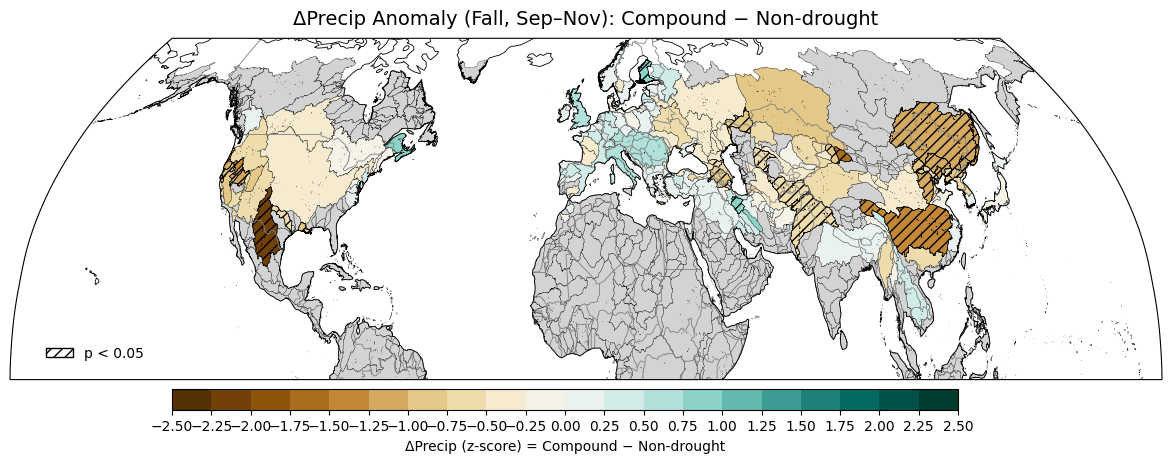

In [36]:
plot_global_delta_ppt(
    "dPPT_fall_comp_minus_norm",
    "ΔPrecip Anomaly (Fall, Sep–Nov): Compound − Non-drought",
    p_dict=p_ppt_by_basin["fall"],
    alpha=0.05
)

95 significant basins (p < 0.05) for ΔPrecip Anomaly (Winter, Dec–Mar): Compound − Non-drought


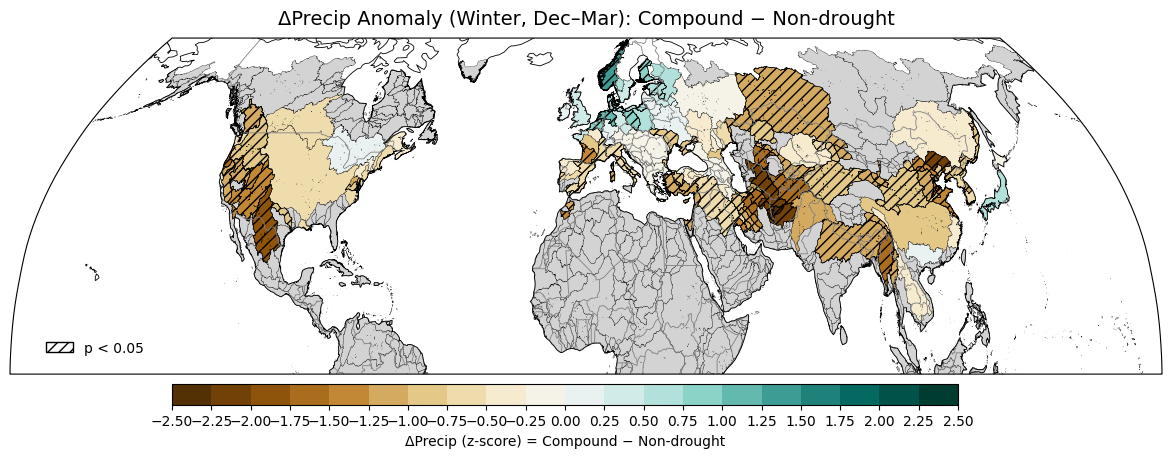

In [37]:
plot_global_delta_ppt(
    "dPPT_winter_comp_minus_norm",
    "ΔPrecip Anomaly (Winter, Dec–Mar): Compound − Non-drought",
    p_dict=p_ppt_by_basin["winter"],
    alpha=0.05
)

133 significant basins (p < 0.05) for ΔPrecip Anomaly (Summer, Apr–Sep): Compound − Non-drought


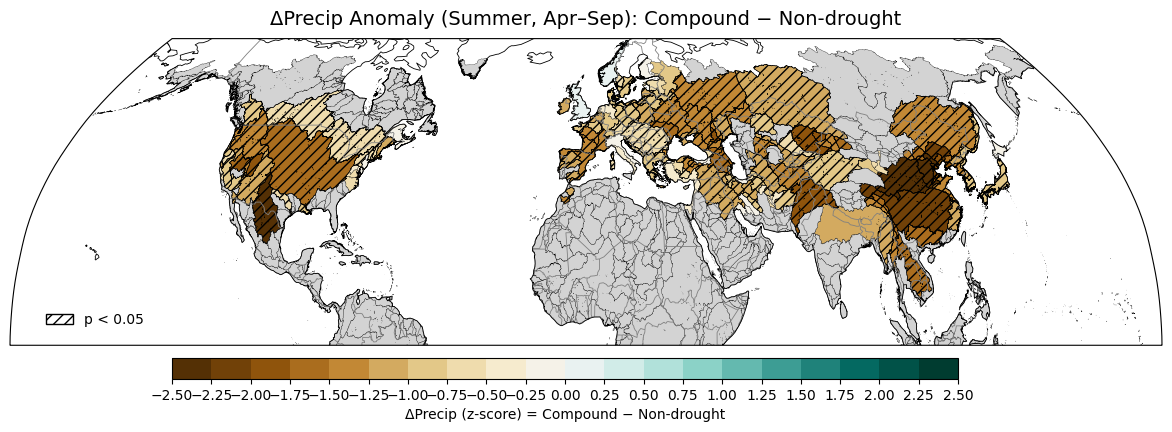

In [38]:
plot_global_delta_ppt(
    "dPPT_summer_comp_minus_norm",
    "ΔPrecip Anomaly (Summer, Apr–Sep): Compound − Non-drought",
    p_dict=p_ppt_by_basin["summer"],
    alpha=0.05
)

Winter stats:
{'n_valid': 173, 'n_sig': 95, 'n_inc': 10, 'n_dec': 85, 'pct_sig': 54.91329479768786, 'pct_inc': 5.780346820809249, 'pct_dec': 49.13294797687861}

Summer stats:
{'n_valid': 173, 'n_sig': 133, 'n_inc': 0, 'n_dec': 133, 'pct_sig': 76.878612716763, 'pct_inc': 0.0, 'pct_dec': 76.878612716763}
Saved figure to: /home/mgurazada/snowdroughts_thirst/code/certain/Fig_3_1.png


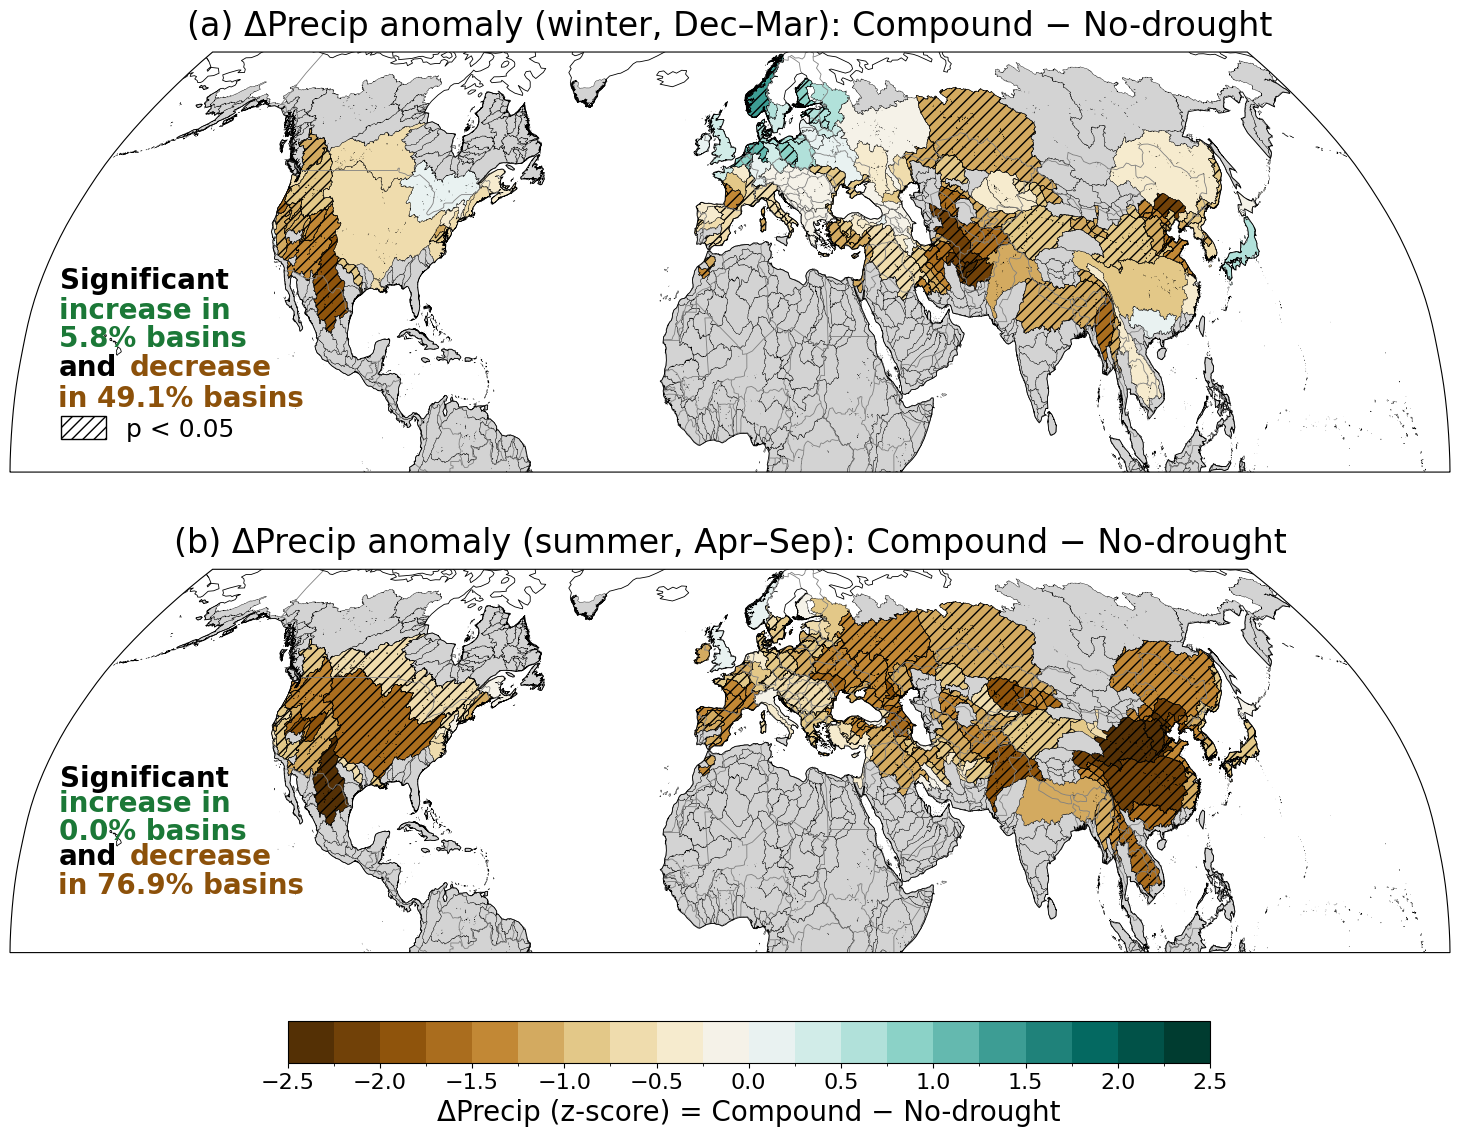

In [39]:
import os
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ------------------------------------------------------------
# Helper: count significant positive / negative basins
# Percentages are relative to basins with non-missing values
# in the plotted column for that season.
# ------------------------------------------------------------
def get_sig_stats(gdf, column, p_dict, alpha=0.05):
    pvals = gdf["MAIN_BAS"].map(p_dict)

    valid = gdf[column].notna()
    sig = valid & pvals.notna() & (pvals < alpha)

    sig_inc = sig & (gdf[column] > 0)
    sig_dec = sig & (gdf[column] < 0)

    n_valid = int(valid.sum())
    n_sig = int(sig.sum())
    n_inc = int(sig_inc.sum())
    n_dec = int(sig_dec.sum())

    pct_sig = 100 * n_sig / n_valid if n_valid > 0 else np.nan
    pct_inc = 100 * n_inc / n_valid if n_valid > 0 else np.nan
    pct_dec = 100 * n_dec / n_valid if n_valid > 0 else np.nan

    return {
        "n_valid": n_valid,
        "n_sig": n_sig,
        "n_inc": n_inc,
        "n_dec": n_dec,
        "pct_sig": pct_sig,
        "pct_inc": pct_inc,
        "pct_dec": pct_dec,
    }


# ------------------------------------------------------------
# Panel plotting function
# ------------------------------------------------------------
def plot_delta_ppt_panels_vertical(
    gdf,
    winter_col="dPPT_winter_comp_minus_norm",
    summer_col="dPPT_summer_comp_minus_norm",
    winter_pdict=None,
    summer_pdict=None,
    alpha=0.05,
    outname="Fig_3_1.png"
):
    # shared color scale
    vmin, vmax = -2.5, 2.5
    bounds = np.arange(vmin, vmax + 0.25, 0.25)
    tick_vals = np.arange(vmin, vmax + 0.5, 0.5)

    cmap = plt.get_cmap("BrBG", len(bounds) - 1)
    norm = mcolors.BoundaryNorm(bounds, ncolors=cmap.N, clip=True)

    # stats
    winter_stats = get_sig_stats(gdf, winter_col, winter_pdict, alpha=alpha)
    summer_stats = get_sig_stats(gdf, summer_col, summer_pdict, alpha=alpha)

    print("Winter stats:")
    print(winter_stats)
    print("\nSummer stats:")
    print(summer_stats)

    # larger figure
    fig, axes = plt.subplots(
        nrows=2,
        ncols=1,
        figsize=(15, 13),
        subplot_kw={"projection": ccrs.Robinson()}
    )

    # font sizes
    title_fs = 24
    annotation_fs = 20
    legend_fs = 18
    cbar_label_fs = 20
    cbar_tick_fs = 16

    panel_info = [
        (
            axes[0],
            winter_col,
            winter_pdict,
            "(a) ΔPrecip anomaly (winter, Dec–Mar): Compound − No-drought",
            winter_stats
        ),
        (
            axes[1],
            summer_col,
            summer_pdict,
            "(b) ΔPrecip anomaly (summer, Apr–Sep): Compound − No-drought",
            summer_stats
        )
    ]

    for i, (ax, column, p_dict, title, stats) in enumerate(panel_info):
        ax.set_global()

        ax.add_feature(cfeature.BORDERS, linewidth=0.6, edgecolor="gray")
        ax.add_feature(cfeature.COASTLINE, linewidth=0.6)

        # main polygons
        gdf.plot(
            ax=ax,
            column=column,
            cmap=cmap,
            norm=norm,
            edgecolor="black",
            linewidth=0.25,
            legend=False,
            transform=ccrs.PlateCarree(),
            missing_kwds={
                "color": "lightgray",
                "edgecolor": "black"
            },
        )

        # hatching for significance
        if p_dict is not None:
            sig_ids = [
                bid for bid, p in p_dict.items()
                if (p is not None) and np.isfinite(p) and (p < alpha)
            ]

            sig_gdf = gdf[gdf["MAIN_BAS"].isin(sig_ids)]

            if not sig_gdf.empty:
                sig_gdf.plot(
                    ax=ax,
                    facecolor="none",
                    edgecolor="black",
                    linewidth=0.3,
                    hatch="///",
                    transform=ccrs.PlateCarree()
                )

        ax.set_title(title, fontsize=title_fs, pad=12)
        ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

        # one compact significance block
        x_text = -172
        
        # Significant
        ax.text(
            x_text-3, 31,
            "Significant",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="black",
            ha="left",
            va="center",
            fontweight="bold"
        )
        
        # increase block
        ax.text(
            x_text, 24,
            f"increase in\n{stats['pct_inc']:.1f}% basins",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="#1b7837",
            ha="left",
            va="center",
            fontweight="bold",
            linespacing=1.0
        )
        
        # "and decrease in" on same line
        y_dec = 18
        
        ax.text(
            x_text+2, y_dec-1,
            "and",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="black",
            ha="left",
            va="center",
            fontweight="bold"
        )
        
        ax.text(
            x_text + 20, y_dec-1,   # shift right so it sits on same line after "and"
            "decrease",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="#8c510a",
            ha="left",
            va="center",
            fontweight="bold"
        )
        
        # second line for decrease %
        ax.text(
            x_text + 3, y_dec-6,
            f"in {stats['pct_dec']:.1f}% basins",
            transform=ccrs.PlateCarree(),
            fontsize=annotation_fs,
            color="#8c510a",
            ha="left",
            va="center",
            fontweight="bold"
        )

        # hatch legend only once
        if i == 0:
            hatch_patch = mpatches.Patch(
                facecolor="white",
                edgecolor="black",
                hatch="///",
                label=f"p < {alpha}"
            )

            ax.legend(
                handles=[hatch_patch],
                loc="lower left",
                bbox_to_anchor=(0.02, 0.02),
                frameon=False,
                fontsize=legend_fs,
                handlelength=1.8,
                handleheight=1.0
            )

    # shared colorbar under bottom panel
    fig.canvas.draw()
    pos2 = axes[1].get_position()

    cax = fig.add_axes([
        pos2.x0 + 0.08,
        pos2.y0 - 0.055,
        pos2.width - 0.16,
        0.032
    ])

    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])

    cb = fig.colorbar(
        sm,
        cax=cax,
        orientation="horizontal",
        boundaries=bounds,
        ticks=tick_vals,
        spacing="proportional"
    )

    cb.set_label(
        "ΔPrecip (z-score) = Compound − No-drought",
        fontsize=cbar_label_fs
    )
    cb.ax.tick_params(labelsize=cbar_tick_fs)

    plt.subplots_adjust(
        top=0.95,
        bottom=0.12,
        left=0.02,
        right=0.98,
        hspace=-0.14
    )

    # save
    outpath = os.path.abspath(outname)
    fig.savefig(outpath, dpi=300, bbox_inches="tight", facecolor="white")
    print(f"Saved figure to: {outpath}")

    plt.show()


plot_delta_ppt_panels_vertical(
    basins_diss,
    winter_col="dPPT_winter_comp_minus_norm",
    summer_col="dPPT_summer_comp_minus_norm",
    winter_pdict=p_ppt_by_basin["winter"],
    summer_pdict=p_ppt_by_basin["summer"],
    alpha=0.05,
    outname="Fig_3_1.png"
)

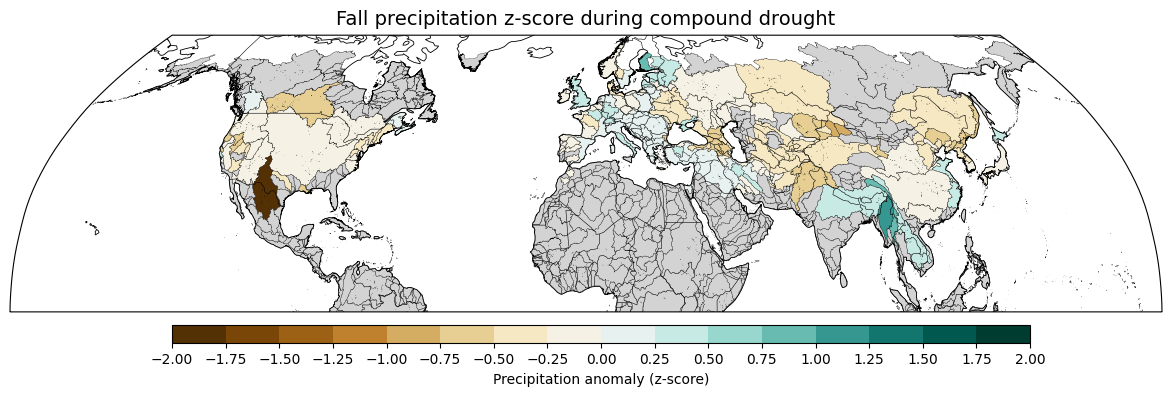

In [40]:
bounds = np.arange(-2, 2.25, 0.25)
cmap = plt.get_cmap("BrBG", len(bounds) - 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig = plt.figure(figsize=(12, 5))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()

ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)

basins_diss.plot(
    ax=ax,
    column="fall_comp",
    cmap=cmap,
    norm=norm,
    edgecolor="black",
    linewidth=0.2,
    legend=False,
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "edgecolor": "black"
    }
)

ax.set_title(
    "Fall precipitation z-score during compound drought",
    fontsize=14,
    pad=8
)

ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

# consistent colorbar placement relative to map
fig.canvas.draw()
pos = ax.get_position()
cax = fig.add_axes([pos.x0 + 0.03, pos.y0 - 0.12, pos.width - 0.06, 0.035])

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, cax=cax, orientation="horizontal", ticks=bounds)
cb.set_label("Precipitation anomaly (z-score)")

plt.subplots_adjust(top=0.90, bottom=0.08, left=0.02, right=0.98)
plt.show()

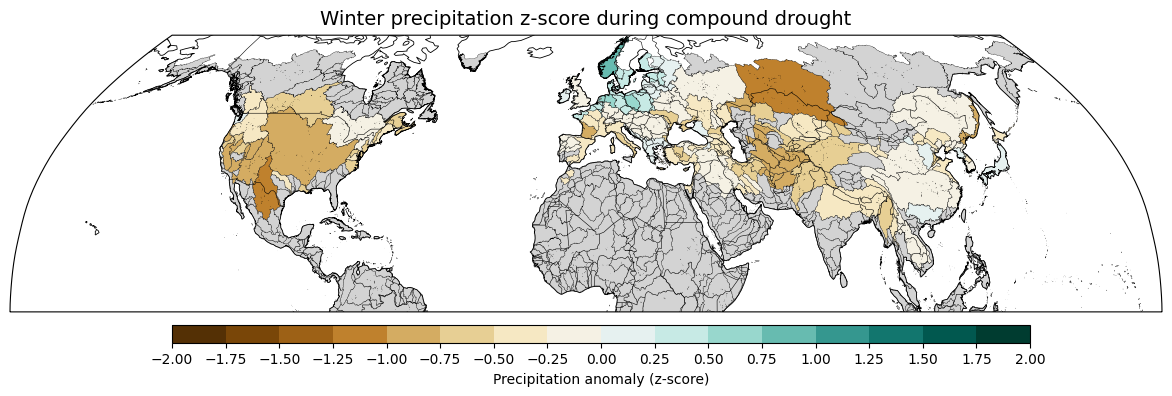

In [41]:
bounds = np.arange(-2, 2.25, 0.25)
cmap = plt.get_cmap("BrBG", len(bounds) - 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig = plt.figure(figsize=(12, 5))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()

ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)

basins_diss.plot(
    ax=ax,
    column="winter_comp",
    cmap=cmap,
    norm=norm,
    edgecolor="black",
    linewidth=0.2,
    legend=False,
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "edgecolor": "black"
    }
)

ax.set_title(
    "Winter precipitation z-score during compound drought",
    fontsize=14,
    pad=8
)

ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

# consistent colorbar placement relative to map
fig.canvas.draw()
pos = ax.get_position()
cax = fig.add_axes([pos.x0 + 0.03, pos.y0 - 0.12, pos.width - 0.06, 0.035])

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, cax=cax, orientation="horizontal", ticks=bounds)
cb.set_label("Precipitation anomaly (z-score)")

plt.subplots_adjust(top=0.90, bottom=0.08, left=0.02, right=0.98)
plt.show()

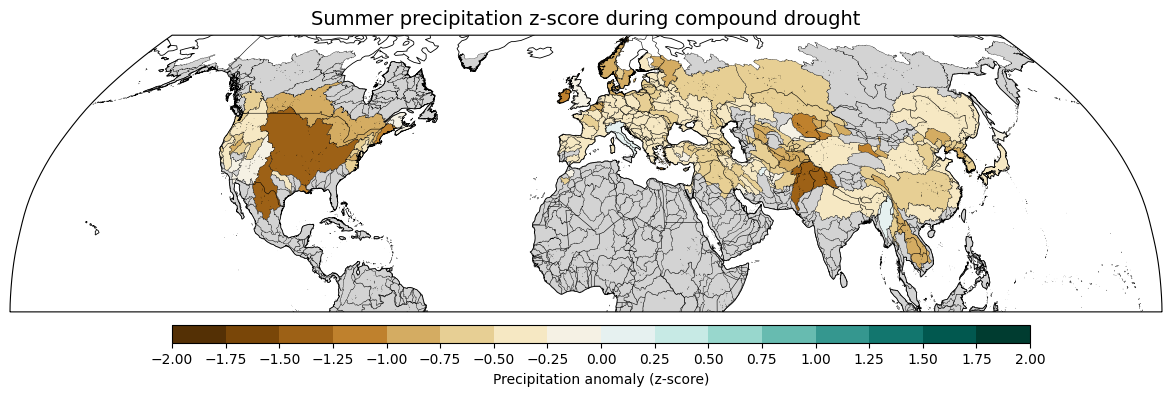

In [42]:
bounds = np.arange(-2, 2.25, 0.25)
cmap = plt.get_cmap("BrBG", len(bounds) - 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig = plt.figure(figsize=(12, 5))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()

ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)

basins_diss.plot(
    ax=ax,
    column="summer_comp",
    cmap=cmap,
    norm=norm,
    edgecolor="black",
    linewidth=0.2,
    legend=False,
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "edgecolor": "black"
    }
)

ax.set_title(
    "Summer precipitation z-score during compound drought",
    fontsize=14,
    pad=8
)

ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

# consistent colorbar placement relative to map
fig.canvas.draw()
pos = ax.get_position()
cax = fig.add_axes([pos.x0 + 0.03, pos.y0 - 0.12, pos.width - 0.06, 0.035])

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, cax=cax, orientation="horizontal", ticks=bounds)
cb.set_label("Precipitation anomaly (z-score)")

plt.subplots_adjust(top=0.90, bottom=0.08, left=0.02, right=0.98)
plt.show()

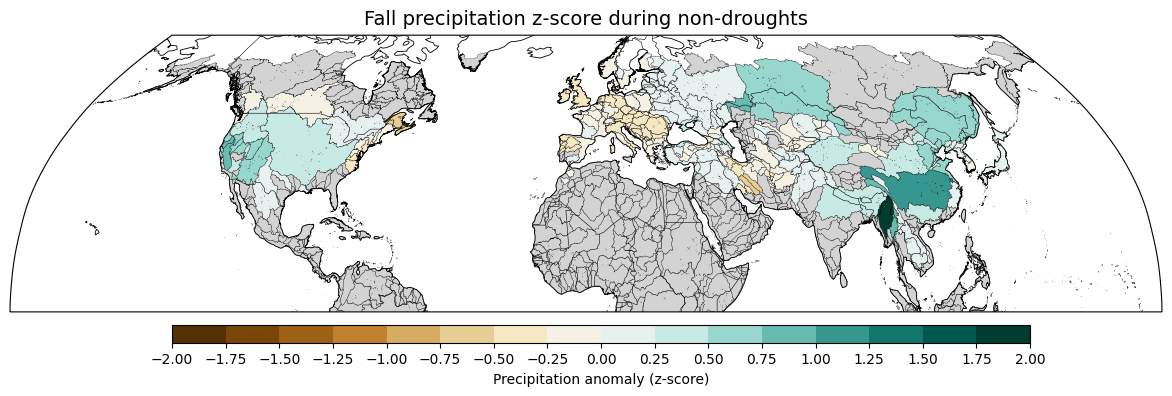

In [43]:
bounds = np.arange(-2, 2.25, 0.25)
cmap = plt.get_cmap("BrBG", len(bounds) - 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig = plt.figure(figsize=(12, 5))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()

ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)

basins_diss.plot(
    ax=ax,
    column="fall_norm",
    cmap=cmap,
    norm=norm,
    edgecolor="black",
    linewidth=0.2,
    legend=False,
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "edgecolor": "black"
    }
)

ax.set_title(
    "Fall precipitation z-score during non-droughts",
    fontsize=14,
    pad=8
)

ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

# consistent colorbar placement relative to map
fig.canvas.draw()
pos = ax.get_position()
cax = fig.add_axes([pos.x0 + 0.03, pos.y0 - 0.12, pos.width - 0.06, 0.035])

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, cax=cax, orientation="horizontal", ticks=bounds)
cb.set_label("Precipitation anomaly (z-score)")

plt.subplots_adjust(top=0.90, bottom=0.08, left=0.02, right=0.98)
plt.show()

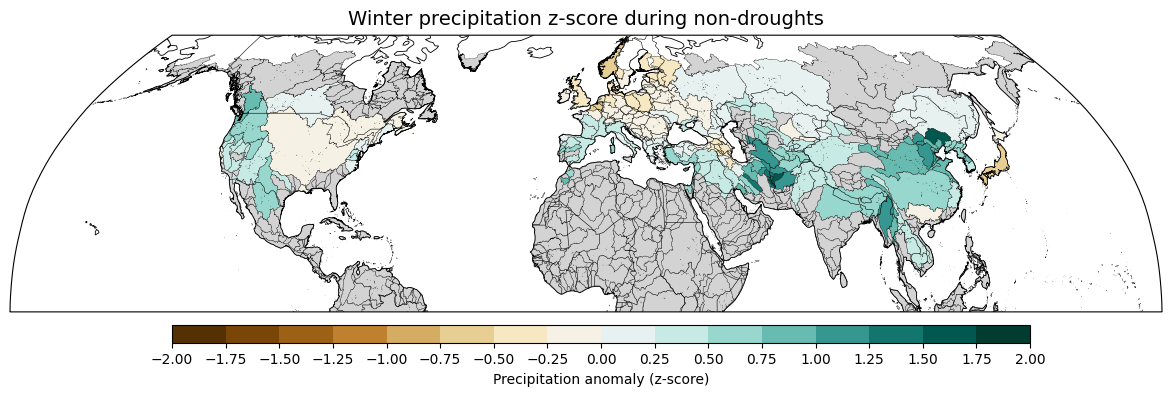

In [44]:
bounds = np.arange(-2, 2.25, 0.25)
cmap = plt.get_cmap("BrBG", len(bounds) - 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig = plt.figure(figsize=(12, 5))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()

ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)

basins_diss.plot(
    ax=ax,
    column="winter_norm",
    cmap=cmap,
    norm=norm,
    edgecolor="black",
    linewidth=0.2,
    legend=False,
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "edgecolor": "black"
    }
)

ax.set_title(
    "Winter precipitation z-score during non-droughts",
    fontsize=14,
    pad=8
)

ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

# consistent colorbar placement relative to map
fig.canvas.draw()
pos = ax.get_position()
cax = fig.add_axes([pos.x0 + 0.03, pos.y0 - 0.12, pos.width - 0.06, 0.035])

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, cax=cax, orientation="horizontal", ticks=bounds)
cb.set_label("Precipitation anomaly (z-score)")

plt.subplots_adjust(top=0.90, bottom=0.08, left=0.02, right=0.98)
plt.show()

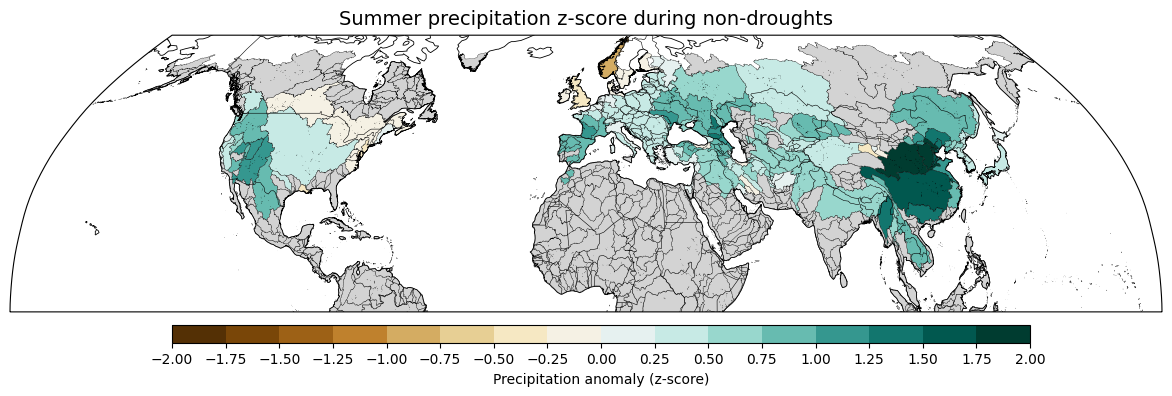

In [45]:
bounds = np.arange(-2, 2.25, 0.25)
cmap = plt.get_cmap("BrBG", len(bounds) - 1)
norm = mcolors.BoundaryNorm(bounds, cmap.N)

fig = plt.figure(figsize=(12, 5))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()

ax.add_feature(cfeature.COASTLINE, linewidth=0.6)
ax.add_feature(cfeature.BORDERS, linewidth=0.4)

basins_diss.plot(
    ax=ax,
    column="summer_norm",
    cmap=cmap,
    norm=norm,
    edgecolor="black",
    linewidth=0.2,
    legend=False,
    transform=ccrs.PlateCarree(),
    missing_kwds={
        "color": "lightgray",
        "edgecolor": "black"
    }
)

ax.set_title(
    "Summer precipitation z-score during non-droughts",
    fontsize=14,
    pad=8
)

ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())

# consistent colorbar placement relative to map
fig.canvas.draw()
pos = ax.get_position()
cax = fig.add_axes([pos.x0 + 0.03, pos.y0 - 0.12, pos.width - 0.06, 0.035])

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cb = fig.colorbar(sm, cax=cax, orientation="horizontal", ticks=bounds)
cb.set_label("Precipitation anomaly (z-score)")

plt.subplots_adjust(top=0.90, bottom=0.08, left=0.02, right=0.98)
plt.show()

In [46]:
out_dir = "conditional_prob_inputs"
os.makedirs(out_dir, exist_ok=True)

# save winter precip basin-year data
with open(os.path.join(out_dir, "ppt_winter_by_basin.pkl"), "wb") as f:
    pickle.dump(ppt_winter_by_basin, f)

# save basin ID order
basin_lookup = pd.DataFrame({
    "region": np.arange(len(main_ids_valid)),
    "MAIN_BAS": main_ids_valid
})

basin_lookup.to_csv(
    os.path.join(out_dir, "basin_region_lookup.csv"),
    index=False
)

print("Saved precip inputs")

Saved precip inputs


In [72]:
ppt_winter_fraction_by_basin = {}

for bid in main_ids_valid:
    pr_ts = ppt_by_basin.get(bid)
    if pr_ts is None:
        continue

    pr_ts = pr_ts.assign_coords(wy=water_year(pr_ts.time))

    # winter / water-year annual
    is_winter = pr_ts.time.dt.month.isin([10, 11, 12, 1, 2, 3])
    is_annual = pr_ts.time.dt.month.isin([10, 11, 12, 1, 2, 3, 4, 5, 6, 7, 8, 9])

    pr_winter = pr_ts.where(is_winter, drop=True).groupby("wy").sum("time")
    pr_annual = pr_ts.where(is_annual, drop=True).groupby("wy").sum("time")

    f_winter = pr_winter / pr_annual

    # climatological mean fraction per basin
    ppt_winter_fraction_by_basin[bid] = f_winter.mean("wy", skipna=True)

In [73]:
basins_diss["winter_frac"] = np.nan
basins_diss["winter_frac_pct"] = basins_diss["winter_frac"] * 100

for bid, val in ppt_winter_fraction_by_basin.items():
    if val is not None:
        basins_diss.loc[
            basins_diss["HYBAS_ID"] == bid,
            "winter_frac_pct"
        ] = float(val.values) * 100

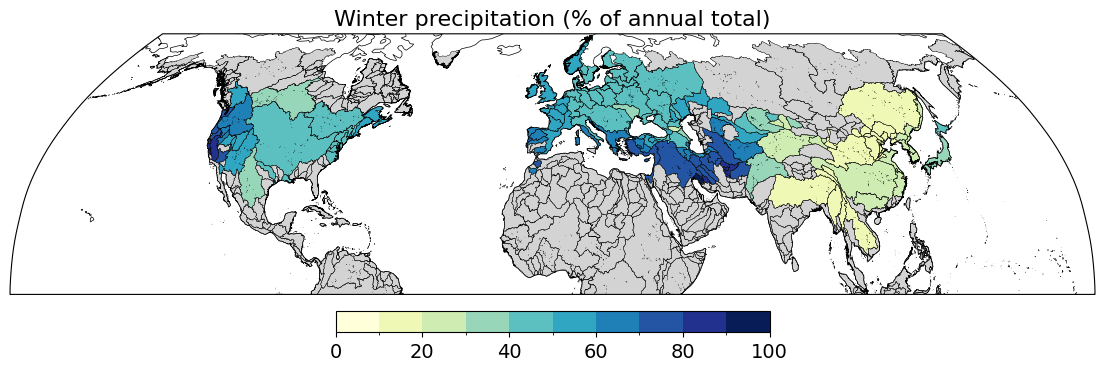

In [74]:
fig = plt.figure(figsize=(14,7))
ax = plt.axes(projection=ccrs.Robinson())
ax.set_global()

bins = np.arange(0, 101, 10)

cmap = plt.get_cmap("YlGnBu", len(bins)-1)

norm = mcolors.BoundaryNorm(
    boundaries=bins,
    ncolors=cmap.N,
    clip=True
)

basins_diss.plot(
    column="winter_frac_pct",
    cmap=cmap,
    norm=norm,
    linewidth=0.2,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    missing_kwds={"color":"lightgray"},
    ax=ax
)

basins_diss.boundary.plot(
    ax=ax,
    linewidth=0.15,
    color="black",
    transform=ccrs.PlateCarree()
)

ax.set_extent([-180, 180, 0, 70], crs=ccrs.PlateCarree())
ax.coastlines(linewidth=0.5)

cb = plt.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax,
    orientation="horizontal",
    pad=0.03,
    shrink=0.4
)
cb.ax.tick_params(labelsize=14)

plt.title("Winter precipitation (% of annual total)", fontsize=16)
plt.show()